In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [6]:
df.isna().sum() # We check for missing values

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [9]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [10]:
X = df.drop(columns='charges')
y= df['charges']

In [11]:
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns

In [19]:
# See the categorical features

for c in df.select_dtypes(include=['object']):
  print(f'{df[c].value_counts().to_frame('count')}')

        count
sex          
male      675
female    662
        count
smoker       
no       1063
yes       274
           count
region          
southeast    364
southwest    325
northwest    324
northeast    324


In [22]:
# correlation matrix
corr_mat = df.select_dtypes(include=['int64', 'float64']).corr().sort_values('charges', ascending=False)
corr_mat

,age,bmi,children,charges
charges,0.298308,0.198401,0.067389,1.000000
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389


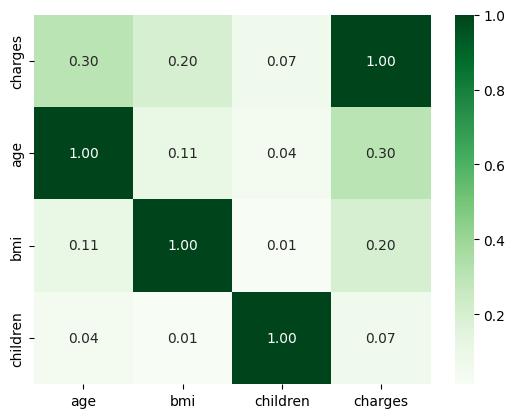

In [25]:
sns.heatmap(corr_mat,annot=True, fmt='.2f', cmap='Greens')
plt.show()

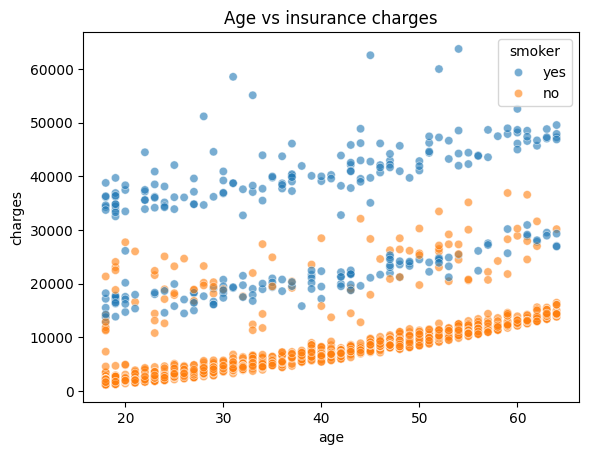

In [31]:
sns.scatterplot(data=df,x="age",y="charges",hue="smoker",alpha=.6); plt.title("Age vs insurance charges")
plt.show()

In [32]:
df['age_squared'] = df['age']**2 # we create e new feature for age as it is highly correlated with charges

<Axes: xlabel='charges'>

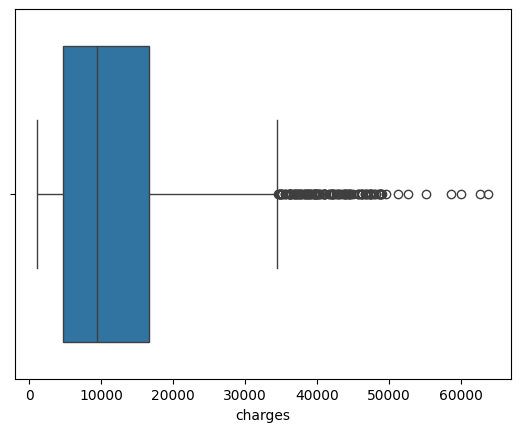

In [26]:
sns.boxplot(data=df, x='charges') # we can see some outliers here...but we shouldnt just remove them because they could represent useful infos

In [30]:
for c in df.select_dtypes(include='object'): # one hot code everything
  print(c)
  display(df[c].unique())

sex


array(['female', 'male'], dtype=object)

smoker


array(['yes', 'no'], dtype=object)

region


array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In [34]:
df.head()

,age,sex,bmi,children,smoker,region,charges,age_squared
0,19,female,27.900,0,yes,southwest,16884.92400,361
1,18,male,33.770,1,no,southeast,1725.55230,324
2,28,male,33.000,3,no,southeast,4449.46200,784
3,33,male,22.705,0,no,northwest,21984.47061,1089
4,32,male,28.880,0,no,northwest,3866.85520,1024


In [36]:
X = df.drop(columns= ['charges']); y=df['charges']; X.shape, y.shape

((1337, 7), (1337,))

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [48]:
num = X.select_dtypes(include=['int64', 'float64']).columns
cat = X.select_dtypes(include=['object']).columns

In [49]:
num,cat

(Index(['age', 'bmi', 'children', 'age_squared'], dtype='object'),
 Index(['sex', 'smoker', 'region'], dtype='object'))

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

num_pipe = Pipeline(
    steps=[
        ('rob', RobustScaler())
    ]
)

cat_pipe = Pipeline(
    steps=[
        ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first'))
    ]
)

prep = ColumnTransformer(
    transformers=[
        ('num', num_pipe, num),
        ('cat', cat_pipe, cat)
    ]
)

In [51]:
from sklearn.ensemble import RandomForestRegressor # Using RF regressor because it can capture non linear and complex retationship very well while reducing variance in the data
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

model = Pipeline(
    steps=[
        ('preprocessor', prep),
        ('rfr', RandomForestRegressor(n_estimators=300,random_state=42))
    ]
)

model.fit(X_train, y_train)
y_pred_base = model.predict(X_test)

r2 = r2_score(y_test, y_pred_base)
mae = mean_absolute_error(y_test, y_pred_base)
rmse = root_mean_squared_error(y_test, y_pred_base)

print('R2: ', r2)
print('MAE: ', mae)
print('RMSE: ', rmse)

R2:  0.8791559150458101
MAE:  2664.791785365297
RMSE:  4712.3065916629575


In [52]:
# Lets use cross validation to find the the hyper parameters. We will use gridsearchcv

from sklearn.model_selection import GridSearchCV

param_grid = {
    'rfr__n_estimators': [200, 300, 500],
    'rfr__max_depth': [None, 10, 20],
    'rfr__min_samples_split': [2, 5],
    'rfr__min_samples_leaf': [1, 2]
}

grid = GridSearchCV(
    estimator = model,
    cv=5,
    n_jobs=-1,
    scoring='neg_root_mean_squared_error',
    param_grid=param_grid,
    verbose=2
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('rob',
                                                                                          RobustScaler())]),
                                                                         Index(['age', 'bmi', 'children', 'age_squared'], dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('ohe',
                                                                                          OneHotEncoder(drop='first',
                                                                                                        handle_unknown='ignore'))]),
                                                                         Index(['sex', 'smoker', 'region'], dtype='object'))])),
                                       ('rfr',
                                        RandomForestRegressor(n_estimators=300,
                                                              random_state=42))]),
             n_jobs=-1,
             param_grid={'rfr__max_depth': [None, 10, 20],
                         'rfr__min_samples_leaf': [1, 2],
                         'rfr__min_samples_split': [2, 5],
                         'rfr__n_estimators': [200, 300, 500]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [53]:
# cv paramters and metrics on validation set
results = pd.DataFrame(grid.cv_results_)
results = results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]].copy()
results['mean_test_RMSE'] = -results['mean_test_score']
results = results.sort_values('rank_test_score')
results.head(10)

,params,mean_test_score,std_test_score,rank_test_score,mean_test_RMSE
23,"{'rfr__max_depth': 10, 'rfr__min_samples_leaf'...",-4813.497557,332.786597,1,4813.497557
21,"{'rfr__max_depth': 10, 'rfr__min_samples_leaf'...",-4813.814803,324.179666,2,4813.814803
33,"{'rfr__max_depth': 20, 'rfr__min_samples_leaf'...",-4816.672818,319.637658,3,4816.672818
9,"{'rfr__max_depth': None, 'rfr__min_samples_lea...",-4816.833671,319.562099,4,4816.833671
22,"{'rfr__max_depth': 10, 'rfr__min_samples_leaf'...",-4817.470953,331.518539,5,4817.470953
35,"{'rfr__max_depth': 20, 'rfr__min_samples_leaf'...",-4818.578502,325.948066,6,4818.578502
11,"{'rfr__max_depth': None, 'rfr__min_samples_lea...",-4818.646409,325.913771,7,4818.646409
34,"{'rfr__max_depth': 20, 'rfr__min_samples_leaf'...",-4820.924948,324.840686,8,4820.924948
10,"{'rfr__max_depth': None, 'rfr__min_samples_lea...",-4821.037764,324.781146,9,4821.037764
18,"{'rfr__max_depth': 10, 'rfr__min_samples_leaf'...",-4821.730056,315.166883,10,4821.730056


In [54]:
best_model = grid.best_estimator_
best_param = grid.best_params_
best_cv_rmse = grid.best_score_

print(best_param)
print(-best_cv_rmse)

{'rfr__max_depth': 10, 'rfr__min_samples_leaf': 2, 'rfr__min_samples_split': 5, 'rfr__n_estimators': 500}
4813.497557319088


In [55]:
#tuned model metrics

y_pred_grid = best_model.predict(X_test)

r2_grid = r2_score(y_test, y_pred_grid)
mae_grid = mean_absolute_error(y_test, y_pred_grid)
rmse_grid = root_mean_squared_error(y_test, y_pred_grid)

print('R2: ', r2_grid)
print('MAE: ', mae_grid)
print('RMSE: ', rmse_grid)

R2:  0.8914374280314883
MAE:  2529.9067125399806
RMSE:  4466.433804178932


In [56]:
compare= pd.DataFrame({
    'model': ['base random forest regressor', 'tuned random forest regressor'],
    'R2': [r2, r2_grid],
    'MAE': [mae, mae_grid],
    'RMSE': [rmse, rmse_grid]
})

compare

,model,R2,MAE,RMSE
0,base random forest regressor,0.879156,2664.791785,4712.306592
1,tuned random forest regressor,0.891437,2529.906713,4466.433804


we can see that tuned random forest achieved a better r2 than the base one..so we will save that

In [57]:
import pickle
filename ='best random forest.pkl'

with open(filename, 'wb') as file:
  pickle.dump(best_model, file)